# Data Preparation

It is important to run this code block before working on the rest of the notebook. It reads from an updated dataset that contains selected demographics columns and the average values for respective sections.
Refer to the [VCQ code book](https://docs.google.com/document/d/1uYfUuUsPVQyD3puVvbIMjamYuVPr_f4gtJuSB5Wj-WA/edit) for questions in related sections.

In [3]:
# Step 1: Collect the original data into a DataFrame object
import pandas as pd
pd.options.display.float_format = '{:.2f}'.format

df = pd.read_csv('https://raw.githubusercontent.com/qarnac/cs201/refs/heads/main/vcq_recoded_means.csv')
df.head(10)


,gender,relationship,children,classstanding,past_employed,current_employed,politics,religion,social_media,procrastinate,...,conflict_resolution,significant_other,job_security,job_satisfaction,job_mobility,work_demands,supervisors,coworkers,work_impact_school,school_impact_work
0,Male,No,No,Sophomore,Yes,Yes,NaN,No,3.75,3.11,...,NaN,NaN,5.00,3.40,4.20,4.62,4.83,4.33,4.00,3.00
1,Female,Yes,No,Junior,Yes,Yes,moderate,No,1.00,3.62,...,4.75,6.00,4.80,4.00,3.20,4.75,5.33,6.00,5.00,5.00
2,Male,No,No,Junior,No,No,moderate,Yes,4.25,3.44,...,NaN,NaN,4.00,3.40,NaN,NaN,NaN,NaN,2.50,2.50
3,Female,No,No,Sophomore,No,No,moderate,No,4.75,1.78,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Female,No,No,Sophomore,No,No,moderate,Yes,4.75,3.33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Female,No,No,Junior,Yes,Yes,NaN,Yes,1.50,2.33,...,NaN,NaN,3.80,4.20,3.20,5.00,3.67,5.00,5.00,5.50
6,Male,Yes,No,Junior,Yes,Yes,conservative,Yes,3.25,3.67,...,4.50,5.75,3.80,3.60,4.40,2.38,5.67,5.33,4.00,3.50
7,Female,No,No,Senior,Yes,Yes,liberal,Yes,4.25,3.89,...,NaN,NaN,4.20,4.40,4.60,2.50,4.33,4.17,4.50,2.00
8,Female,Yes,No,Junior,Yes,Yes,moderate,Yes,4.50,2.44,...,5.75,4.75,3.40,1.00,3.40,3.12,3.33,5.50,4.50,1.50
9,Male,Yes,No,Senior,Yes,Yes,liberal,No,2.50,1.89,...,6.00,5.75,4.20,2.00,3.60,4.00,5.33,5.67,4.50,1.50


We performed ANOVA tests to help us see whether students of different categorical groups felt differently on selected sections of the survey. Today, we'll look at how responses for one section of the survey may be related to responses in another section of the survey. For example,
*  Do students who procrastinate more tend to use more social media?
*  Do students with higher stress tend to procrastinate more?

# Scatter plots

Scatter plots are a powerful way to explore relationships between two numerical variables. The `plot` function we used for bar charts and histograms can also be used to create a scatter plot as shown in the following code block.

*  We need to set the `kind` parameter to `'scatter'` instead of `'bar'` or `'hist'`.
*  The `x` parameter specifies the column whose values will be used for the x-axis.
*  The `y` parameter specifies the column whose values will be used for the y-axis.
*  The `figsize` parameter specifies the width and height of the figure.
*  The `alpha` parameter specifies the level of transparency for each dot, 0 for fully transparent and 1 for fully opaque. The default value is 1.
*  The `s` parameter specifies the size of the dots, 20 for a small dot, 50 - 80 for a medium dot, and 150 - 300 for a large dot.
*  The `grid` parameter specifies whether to show a grid in the background. The default value is `False`.

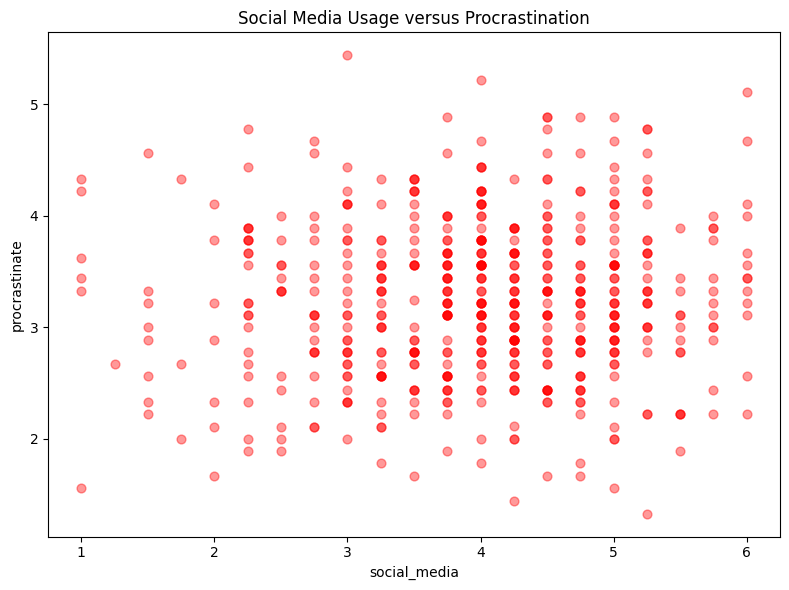

In [ ]:
import matplotlib.pyplot as plt     # import appropriate library

# create a scatter plot to help visualize whether students who spend more
# time on social media are more likely to procrastinate
df.plot(kind='scatter',             #Indicate the kind of plot to be generated
        x='social_media',           #Identify the column for the x_axis
        y='procrastinate',          #Identify the column for the y-axis
        figsize=(8, 6),             #Set up the width and height of the graph
        title='Social Media Usage versus Procrastination',  #Set up the title of the graph
        s=40,                       #Indicate the size of each dot
        alpha=0.4,                  #Indicate the level of transparency
        color='red'                #Indicate the color for the dots
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

Each dot represents one student who completed the questionnaire. The x-coordinate shows that student's average social media score, and the y-coordinate shows that student's average procrastination score. Unlike measurements such as height or income, these scores are averages of Likert-scale responses.

*  The **social media** score is based on only 4 questions, so the possible averages occur in increments of 0.25 (for example, 2.75, 3.00, 3.25, and 3.50). As a result, the dots line up in vertical bands rather than being spread continuously across the x-axis.
*  The **procrastination** score is based on 9 questions, so there are many more possible average values. This creates a much smoother distribution along the y-axis.

There are a few observations we can make directly from the plot:

*  There are many students with social media scores between about 3 and 5, suggesting most students are moderate to frequent social media users.
*  The vertical bands occur because many students have exactly the same social media average. Students with similar social media scores can have quite different procrastination scores.
*  Some bands are darker and denser than others because multiple students have nearly identical scores and their dots overlap.
*  The center of the clouds appears to rise slightly from left to right.

This scatterplot suggests a positive relationship between social media usage and procrastination. In general, students who report higher social media usage also tend to report higher levels of procrastination.

However, the relationship does not appear to be very strong. There is substantial variation in procrastination scores at every level of social media usage. This means that social media usage alone does not explain most of the differences in procrastination among students. The scatterplot provides some visual evidence that the answer may be "yes," but it is difficult to determine the strength of the relationship by eye alone. This motivates the need for a numerical measure, such as a correlation coefficient, to summarize the direction and strength of the relationship.

The `seaborn` library also supports a function to generate scatter plots. This is illustrated in the following code block.

*  The name of the function is `scatterplot`.
*  The `data` parameter specifies the dataset used.
*  The `x` and `y` parameters specify the columns of the dataset for the x- and y-axis.
*  The `s`, `alpha`, and `color` parameters are the same as the df.plot function.
*  Note that we need to specify the figure size and title outside of the `sns.scatterplot` function.


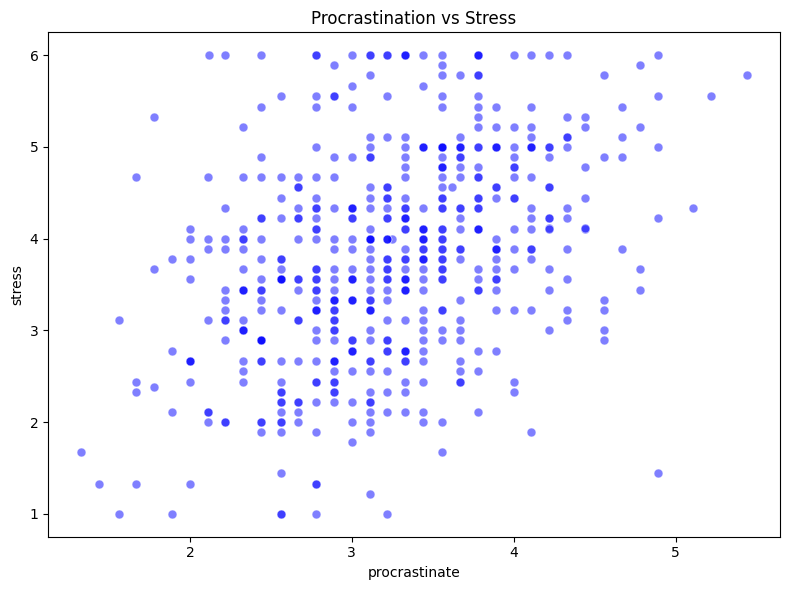

In [ ]:
import matplotlib.pyplot as plt     # import appropriate library
import seaborn as sns

plt.figure(figsize=(8, 6))
plt.title('Procrastination vs Stress')

# create a scatter plot
sns.scatterplot(data=df,        #Indicate the kind of plot to be generated
        x='procrastinate',      #Identify the column for the x_axis
        y='stress',             #Identify the column for the y-axis
        s=40,                   #Indicate the size of each dot
        alpha=0.5,              #Indicate the level of transparency
        color='blue',           #Indicate the color for the dots
)


plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

Again, every dot represents one student.

*  The horizontal position shows the student's average procrastination score.
*  The vertical position shows the student's average stress score.
*  Students with similar procrastination scores reported different stress levels. This suggests that factors other than procrastination also influence stress.
*  Most students have moderate levels of both procrastination and stress. The highest concentration of points appears near the middle of the plot.

The overall pattern slopes upward from left to right, more than the previous scatter plot. Higher procrastination scores tend to occur alongside higher stress scores. The scatterplot suggests a positive relationship between procrastination and stress. In general, students who report procrastinating more tend to report higher levels of stress.

However, the relationship does not appear to be perfect. While the overall trend is upward, there is considerable variation in stress levels among students with similar procrastination scores. This means that procrastination is related to stress, but it is not the only factor affecting students' stress levels.

Based on visual inspection alone, the relationship appears to be moderately positive, but it is difficult to determine its exact strength from the scatterplot. This motivates the use of a correlation coefficient, which provides a numerical measure of the direction and strength of the relationship.

## Practice

In [ ]:
# Create a scatter plot between two other section average of your choice using the df.plot function


In [ ]:
# Create a scatter plot between another two section aveages of your choice using the sns.scatterplot function


**Add a text block** to explain what you learn from the above scatter plots.

*  What question does each of the scatter plot help provide insight?
*  What are common values for each axis?
*  What visible trends between the two section averages do you observe?

# Correlations

Scatter plots help visualize relationship between two numeric columns. However, it can be difficult to describe the relationship precisely. A **Pearson correlation coefficient** is a statistical measure that describes direction and strength of a relationship between two quantitative variables.

*  A positive correlation indicates that higher values of one variable tend to be associated with higher values of another variable.
*  A negative correlation indicates that higher values of one variable tend to be associated with lower values of another variable.

Here are [commonly cited threshold values](https://pmc.ncbi.nlm.nih.gov/articles/PMC6107969/) for correlation:
*  0 - 0.09: Very week, negligible
*  0.1 - 0.29: Weak, small
*  0.3 - 0.49: Moderate, medium
*  0.5 - 1: Strong, large

In sociology, correlation is useful because researchers are often interested in understanding how different aspects of people's lives are connected. For example,

*  Does stronger family satisfaction relate to higher self-esteem?
*  Do students with more stress report lower life satisfaction?
*  Is job security related to procrastination?

While correlation can reveal meaningful relationships, it does not tell us whether one variable causes the other. Instead, it helps us identify patterns that may be worth exploring further.

In [ ]:
coe_socialmedia_procrastinate = df['social_media'].corr(df['procrastinate'])
coe_stress_procrastinate = df['stress'].corr(df['procrastinate'])
print(f'Correlation coefficient between social and procrastination is {coe_socialmedia_procrastinate: .3f}')
print(f'Correlation coefficient between stress and procrastination is {coe_stress_procrastinate: .3f}')


Correlation coefficient between social and procrastination is  0.059
Correlation coefficient between stress and procrastination is  0.385
Correlation coefficient between stress and social media is  0.130


From the above resuluts, we can see that

*  Both social media usage and stress are positively associated with procrastination.
*  The association between stress and procastination is strong than the association between social media usage and procrastination. This is consistent with the scatter plots.

## Practice

In [ ]:
# determine and display correlation coefficients between the section averages in the scatter plots you created


Add a Markdown text block to explain what these coefficients tell you and how they are related to the scatter plots.

# Correlation Matrix

When working with many variables, creating separate scatter plots and calculating correlation for every pair of variables can be time-consuming. A **correlation matrix** is a table that summarizes the correlations among multiple variables. Rather than examining one pair of variables at a time, researchers can quickly see how multiple variables in a study are related. A correlation matrix does not have to include every variable in a dataset. Researchers often select a small group of related variables to investigate a specific question or theory. By focusing on a subset of variables, it becomes easier to identify meaningful patterns and avoid being overwhelmed by information.

In sociology, the choice of variables is guided by the research question being studied. For example, the following code block, the variables selected are related to student well-being, exploring how friendships, stress, self-esteem, and life satisfaction may be related among students.

In [4]:
well_being_columns = ['friend_satisfaction', 'stress', 'esteem', 'life_satisfaction']
corr_matrix = df[well_being_columns].corr()
corr_matrix

,friend_satisfaction,stress,esteem,life_satisfaction
friend_satisfaction,1.00,-0.27,0.27,0.22
stress,-0.27,1.00,-0.49,-0.47
esteem,0.27,-0.49,1.00,0.57
life_satisfaction,0.22,-0.47,0.57,1.00


The **diagonal entries** are all 1.00 because each variable is perfectly correlated with itself. We can ignore these values and focus on other cells when reading a correlation matrix.

*  The correlation between `friend_satisfaction` and `stress` is -0.27. A **negative** correlation indicates students who reported higher satisfaction with their friendships tend to report lower stress levels.
*  The correlation between `friend_satisfaction` and `esteem` is 0.27. A **positive** correlation indicates students who reported higher satisfaction with their friendships tend to report higher self esteem.
*  The correlation between `esteem` and `stress` is -0.49, indicating a **stronger** negative correlation than the negative correlation between `friend_satisfaction` and `stress`.
*  The correlation between `life_satifaction` and `esteem` is 0.57, indicating a strong positive correlation than the positive correlation between `friend_satisfaction` and `esteem`.

Overall, the correlation matrix suggests that stress is associated with lower self-esteem, lower life satisfaction, and lower friendship satisfaction. At the same time, students with higher self-esteem tend to report greater life satisfaction and somewhat stronger friendships. Among these four variables, the strongest relationship is between self-esteem and life satisfaction.

## Practice

In [ ]:
# Choose a few variables that are related to a concern or question you have to create and display the correlation matrix among them.


Add a Markdown text block to explain what you learn from the correlation matrix. For example,

*  Are there negative correlations? What do they mean?
*  Are there positive correlations? What do they mean?
*  Are there weak, moderate, and strong correlations?

# Heatmap

A **heatmap** is a visual representation of a correlation matrix that uses colors to show the **strength** and **direction** of relationships between variables. Typically, warmer colors represent positive correlations, cooler colors represent negative correlations, and lighter colors indicate weak or no relationships. Instead of examining a table of numbers, researchers can quickly identify patterns by looking at the colors.

The following code block shows how to use the `sns.heatmap` function:

*  The `data` parameter specifies the correlation matrix to visualize.
*  The `annot` parameter specifies whether to display the actual values inside each cell.
*  The `cmap` parameter specifies a colormap for the values in the correlation matrix. You can find a complete list of [seaborn palettes](https://www.practicalpythonfordatascience.com/ap_seaborn_palette). For correlation matrix, it would be good to choose a diverging palette: one color for negative correlations, a middle color for near zero correlations, and another color for positive correlations. The `coolwarm` option has blue for negative values, red for positive values, and white for zero. You can also try `BrBG`, `PRGn`, or `PuOr`.   


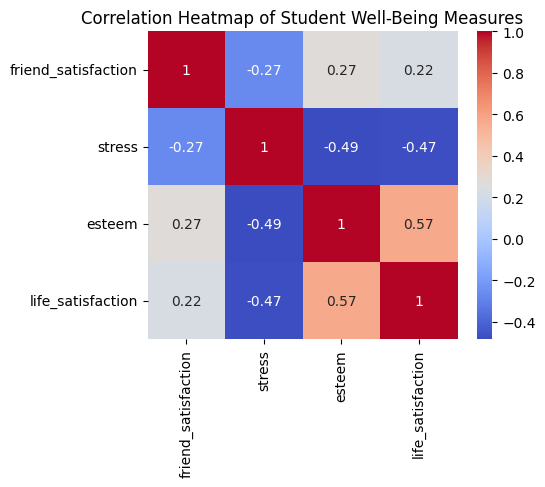

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 4))

sns.heatmap(data=corr_matrix,
    annot=True,      # show correlation values
    cmap='coolwarm' # blue-red color scale
)

plt.title('Correlation Heatmap of Student Well-Being Measures')
plt.show()

Here are what we should note about the heatmap:

*  Each cell shows a correlation between two variables.
*  Different shades of red indicate positive correlations.
*  Different shades of blue indicate negative correlations.
*  Darker colors indicates stronger correlations.

Here are a few things we can easily see from the above heatmap:

*  The strongest red is on the diagnol cells because a variable is perfectly correlated with itself.
*  The strongest positive correlation is between `esteem` and `life_satisfaction`.
*  The weakest positive correlation is between `life_satisfaction` and `friend_satisfaction`.
*  The correlations between stress and esteem/life_satisfaction are pretty close and have similar darkness of blue. The color for the correlation between `stree` and `friend_satisfaction` is a much lighter blue, indicating a weaker correlation.



## Practice

In [ ]:
# Create a heatmap for the correlation matrix you generated in the previous practice.


Add a Markdown text block to explain how the heatmap visualize the correlation matrix. For example,

*  What do the different shades of colors tell you about the correlations?
*  What cell has the darkest color on the positive side? What does that mean?
*  What cell has the lightest color on the positive side? What does that mean?
*  What cell has the darkest color on the negative side? What does that mean?
*  What cell has the lightest color on the negative side? What does that mean?
